# Exercício 1 · Valores Ausentes
**Ciência de Dados — Preparação dos Dados (CRISP-DM)**
**Aluno(a):** Geovanny Mahtus

**Base:** Melbourne Housing Snapshot (`melb_data.csv`), vendas de imóveis em Melbourne, Austrália.

**Contexto:** a base vai ser usada numa análise de preços. Antes disso preciso saber onde faltam dados, quanto falta e, principalmente, *por que* falta, porque é isso que define o tratamento certo para cada coluna.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams['figure.dpi'] = 90

In [2]:
# CARREGAMENTO DOS DADOS
df = pd.read_csv('melb_data.csv')
print(f'{df.shape[0]:,} linhas | {df.shape[1]} colunas')
df.sample(5, random_state=3)

13,580 linhas | 21 colunas


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
2223,Elsternwick,14 Prentice St,3,h,"1,805,000.00",PI,Biggin,10/12/2016,8.50,"3,185.00",...,2.00,1.00,347.00,NaN,NaN,Glen Eira,-37.88,145.01,Southern Metropolitan,"4,898.00"
12053,Kensington,42 Gower St,3,h,"1,060,000.00",S,Nelson,29/07/2017,3.40,"3,031.00",...,1.00,0.00,190.00,NaN,NaN,Melbourne,-37.80,144.93,Northern Metropolitan,"5,263.00"
5552,South Melbourne,203/196 Albert Rd,2,u,"1,050,000.00",VB,Marshall,17/09/2016,2.10,"3,205.00",...,2.00,2.00,0.00,122.00,"2,001.00",Port Phillip,-37.84,144.97,Southern Metropolitan,"5,943.00"
3258,Heidelberg Heights,3/17 Burns Ct,3,h,"600,000.00",VB,Fletchers,22/08/2016,10.50,"3,081.00",...,2.00,2.00,251.00,200.00,"2,012.00",Banyule,-37.74,145.06,Eastern Metropolitan,"2,947.00"
10970,Clayton,2/46 Jaguar Dr,3,h,"729,500.00",S,Nelson,12/08/2017,16.70,"3,168.00",...,1.00,1.00,270.00,218.00,"1,970.00",Monash,-37.93,145.13,South-Eastern Metropolitan,"5,837.00"


In [3]:
# DIAGNÓSTICO INICIAL
visao_geral = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'distintos': df.nunique(),
    'exemplo': df.iloc[0],
})
print('Linhas repetidas:', df.duplicated().sum())
visao_geral

Linhas repetidas: 0


,tipo,nulos,distintos,exemplo
Suburb,str,0,314,Abbotsford
Address,str,0,13378,85 Turner St
Rooms,int64,0,9,2
Type,str,0,3,h
Price,float64,0,2204,"1,480,000.00"
Method,str,0,5,S
SellerG,str,0,268,Biggin
Date,str,0,58,3/12/2016
Distance,float64,0,202,2.50
Postcode,float64,0,198,"3,067.00"


In [4]:
# Mínimos e máximos ajudam a achar valores estranhos que NÃO aparecem como nulos
df.describe().T[['min', '50%', 'max']]

,min,50%,max
Rooms,1.00,3.00,10.00
Price,"85,000.00","903,000.00","9,000,000.00"
Distance,0.00,9.20,48.10
Postcode,"3,000.00","3,084.00","3,977.00"
Bedroom2,0.00,3.00,20.00
Bathroom,0.00,1.00,8.00
Car,0.00,2.00,10.00
Landsize,0.00,440.00,"433,014.00"
BuildingArea,0.00,126.00,"44,515.00"
YearBuilt,"1,196.00","1,970.00","2,018.00"


**O que o diagnóstico mostrou**
- São **13.580 imóveis e 21 colunas**, sem linhas repetidas.
- Apenas **4 colunas** têm nulos: `BuildingArea`, `YearBuilt`, `CouncilArea` e `Car`.
- `Date` está como texto (`'3/12/2016'`), então vou convertê-la quando precisar ordenar por data.
- Além dos nulos, há valores que não fazem sentido: `BuildingArea` com mínimo **0 m²** e máximo **44.515 m²**, e `YearBuilt` com mínimo **1196**. Eles não aparecem no `isna()`, mas são problemas de qualidade (ficam para o tema de outliers; aqui eu só registro).

In [5]:
# RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
nulos = df.isna().sum()
tabela_ausentes = (
    pd.DataFrame({'qtd_ausentes': nulos, 'pct_ausentes': nulos / len(df) * 100})
      .query('qtd_ausentes > 0')
      .sort_values('qtd_ausentes', ascending=False)
)
tabela_ausentes['tipo'] = df[tabela_ausentes.index].dtypes.astype(str)
tabela_ausentes

,qtd_ausentes,pct_ausentes,tipo
BuildingArea,6450,47.50,float64
YearBuilt,5375,39.58,float64
CouncilArea,1369,10.08,str
Car,62,0.46,float64


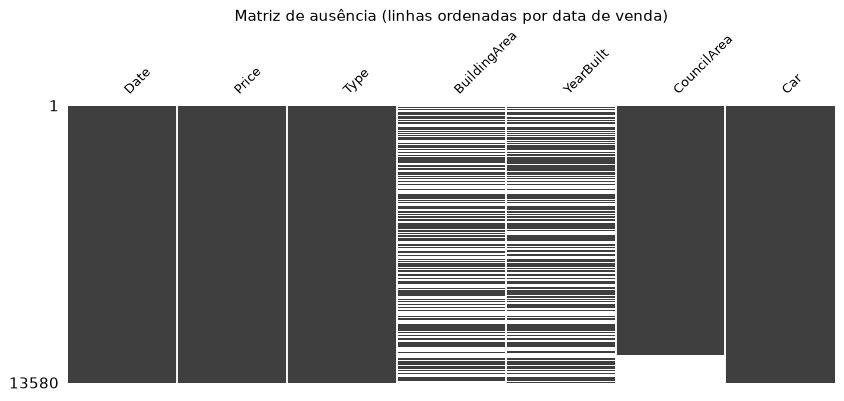

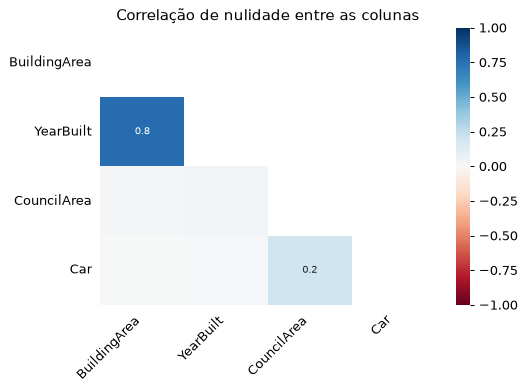

In [6]:
# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA
# Ordeno as linhas por data de venda para ver se a falta de dados muda com o tempo
df_data = df.assign(Date=pd.to_datetime(df['Date'], format='%d/%m/%Y')).sort_values('Date')
cols_nulas = tabela_ausentes.index.tolist()

msno.matrix(df_data[['Date', 'Price', 'Type'] + cols_nulas], figsize=(11, 4), fontsize=10, sparkline=False)
plt.title('Matriz de ausência (linhas ordenadas por data de venda)')
plt.show()

msno.heatmap(df[cols_nulas], figsize=(6, 4), fontsize=10)
plt.title('Correlação de nulidade entre as colunas')
plt.show()

In [7]:
# A falta de BuildingArea/YearBuilt depende de alguma característica do imóvel?
faltas = df[['BuildingArea', 'YearBuilt']].isna()
ano_venda = pd.to_datetime(df['Date'], format='%d/%m/%Y').dt.year
por_grupo = pd.concat({
    'ano da venda': faltas.groupby(ano_venda).mean() * 100,
    'tipo de imóvel': faltas.groupby(df['Type']).mean() * 100,
    'método de venda': faltas.groupby(df['Method']).mean() * 100,
})
por_grupo.columns = ['% sem BuildingArea', '% sem YearBuilt']
print('Linhas sem as DUAS informações ao mesmo tempo:', faltas.all(axis=1).sum())
print('Linhas sem pelo menos uma delas:            ', faltas.any(axis=1).sum())

# CouncilArea: % de nulos por mês de venda (últimos meses da base)
mes = pd.to_datetime(df['Date'], format='%d/%m/%Y').dt.strftime('%Y-%m')
print('\n% de CouncilArea nulo por mês:', (df['CouncilArea'].isna().groupby(mes).mean() * 100).round(1).tail(4).to_dict())
por_grupo

Linhas sem as DUAS informações ao mesmo tempo: 5103
Linhas sem pelo menos uma delas:             6722

% de CouncilArea nulo por mês: {'2017-06': 0.0, '2017-07': 0.1, '2017-08': 53.6, '2017-09': 100.0}


% sem BuildingArea  % sem YearBuilt
ano da venda    2016               43.12            34.63
                2017               51.33            43.91
tipo de imóvel  h                  48.57            42.77
                t                  38.42            31.60
                u                  47.50            32.55
método de venda PI                 44.37            36.38
                S                  49.37            41.58
                SA                 52.17            45.65
                SP                 40.58            33.29
                VB                 46.96            37.20

**Interpretação**
- A ausência está **concentrada**: quase tudo vem de `BuildingArea` (47,5%) e `YearBuilt` (39,6%). `CouncilArea` (10,1%) e `Car` (0,5%) pesam pouco.
- As duas colunas grandes faltam **juntas** (correlação de nulidade alta no heatmap). Na matriz, os buracos de uma acompanham os da outra, o que indica uma causa em comum: provavelmente o anúncio simplesmente não trazia os dados do imóvel.
- `CouncilArea` falta **em bloco no fim da matriz**, ou seja, nas vendas mais recentes: até julho de 2017 a coluna está praticamente completa, em agosto falta em 54% das vendas e em setembro em 100% (ver célula abaixo). A fonte parece ter **parado de registrar** o município a partir dessa data. É uma falta sistemática, ligada ao tempo.
- A taxa de falta **não é igual em todos os grupos**: ela é maior nas vendas de 2017 do que nas de 2016 e varia com o tipo de imóvel e o método de venda. Ou seja, os dados **não faltam completamente ao acaso**. Isso pesa nas decisões abaixo: qualquer tratamento que ignore os grupos pode criar viés.

## Estratégia 1 — Remoção
Antes de escolher, comparei quanto cada forma de remoção custa (tabela abaixo).

**Decisão**
- **Remover as colunas** `BuildingArea` e `YearBuilt`: com 40% a 48% de falta, a maior parte da coluna teria de ser inventada.
- **Remover a coluna** `CouncilArea`, em vez das linhas: a localização do imóvel já está em `Suburb`, `Postcode`, `Regionname` e nas coordenadas, então a coluna é praticamente redundante. Apagar 1.369 linhas para salvar uma informação repetida não compensa.
- **Remover as linhas** sem `Car`: são só 62 (0,5%), um custo desprezível.

In [8]:
# ESTRATÉGIA 1 — REMOÇÃO
df_remocao = df.copy()

# custo de diferentes formas de remover (só para embasar a decisão)
opcoes = {
    'apagar toda linha com nulo': df.dropna(),
    'apagar colunas > 30% + linhas restantes': df.drop(columns=['BuildingArea', 'YearBuilt']).dropna(),
    'apagar colunas > 30% + CouncilArea + linhas sem Car': df.drop(columns=['BuildingArea', 'YearBuilt', 'CouncilArea']).dropna(),
}
custo = pd.DataFrame({
    'linhas': {k: len(v) for k, v in opcoes.items()},
    'colunas': {k: v.shape[1] for k, v in opcoes.items()},
})
custo['% linhas mantidas'] = custo['linhas'] / len(df) * 100
display(custo)

# opção escolhida (a última da tabela)
df_remocao = df_remocao.drop(columns=['BuildingArea', 'YearBuilt', 'CouncilArea'])
df_remocao = df_remocao.dropna(subset=['Car'])
print('df_remocao:', df_remocao.shape, '| nulos restantes:', df_remocao.isna().sum().sum())

,linhas,colunas,% linhas mantidas
apagar toda linha com nulo,6196,21,45.63
apagar colunas > 30% + linhas restantes,12211,19,89.92
apagar colunas > 30% + CouncilArea + linhas sem Car,13518,18,99.54


df_remocao: (13518, 18) | nulos restantes: 0


## Estratégia 2 — Imputação
Em vez de usar **uma única** mediana para a cidade inteira, preencho com a **mediana do grupo** a que o imóvel pertence. Um apartamento (`u`) de 1 quarto e uma casa (`h`) de 5 quartos não deveriam receber a mesma área construída.

| Coluna | Medida | Grupo usado (com reserva se o grupo estiver vazio) | Por quê |
|---|---|---|---|
| `BuildingArea` | mediana | `Type` + `Rooms` → `Type` | numérica e muito assimétrica (máx. 44.515 m²); área depende do tipo e do nº de cômodos |
| `YearBuilt` | mediana | `Suburb` + `Type` → `Regionname` + `Type` → `Type` | bairros foram construídos em épocas parecidas; mediana devolve um ano "real" |
| `Car` | mediana | `Rooms` | contagem inteira; imóveis maiores têm mais vagas |
| `CouncilArea` | **moda** | `Suburb` → `Regionname` | categórica; quase todo bairro pertence a um único município |

Também guardo dois **indicadores de ausência** (`BuildingArea_faltava`, `YearBuilt_faltava`), para não perder a informação de que aquele valor foi estimado. Para comparação, monto ainda uma versão "ingênua" (`df_imput_simples`) com a mediana/moda geral.

In [9]:
# ESTRATÉGIA 2 — IMPUTAÇÃO
df_imputacao = df.copy()

def mediana_por_grupo(base, coluna, niveis):
    # preenche com a mediana do grupo mais específico; se o grupo não tiver valor, tenta o próximo nível
    serie = base[coluna].copy()
    for grupo in niveis:
        serie = serie.fillna(base.groupby(grupo)[coluna].transform('median'))
    return serie.fillna(base[coluna].median())

def moda_por_grupo(base, coluna, niveis):
    serie = base[coluna].copy()
    moda = lambda s: s.mode().iloc[0] if s.notna().any() else np.nan
    for grupo in niveis:
        serie = serie.fillna(base.groupby(grupo)[coluna].transform(moda))
    return serie.fillna(base[coluna].mode().iloc[0])

for col in ['BuildingArea', 'YearBuilt']:
    df_imputacao[col + '_faltava'] = df[col].isna().astype(int)

df_imputacao['BuildingArea'] = mediana_por_grupo(df, 'BuildingArea', [['Type', 'Rooms'], ['Type']])
df_imputacao['YearBuilt']    = mediana_por_grupo(df, 'YearBuilt', [['Suburb', 'Type'], ['Regionname', 'Type'], ['Type']])
df_imputacao['Car']          = mediana_por_grupo(df, 'Car', [['Rooms']])
df_imputacao['CouncilArea']  = moda_por_grupo(df, 'CouncilArea', [['Suburb'], ['Regionname']])

# versão ingênua, só para comparar
df_imput_simples = df.copy()
for col in ['BuildingArea', 'YearBuilt', 'Car']:
    df_imput_simples[col] = df[col].fillna(df[col].median())
df_imput_simples['CouncilArea'] = df['CouncilArea'].fillna(df['CouncilArea'].mode().iloc[0])

print('Nulos restantes (por grupo):', df_imputacao.isna().sum().sum(), '| (ingênua):', df_imput_simples.isna().sum().sum())
recuperados = df.loc[df['CouncilArea'].isna(), 'Suburb'].isin(df.loc[df['CouncilArea'].notna(), 'Suburb']).sum()
print(f"CouncilArea preenchida pelo próprio bairro: {recuperados} de {df['CouncilArea'].isna().sum()}")

Nulos restantes (por grupo): 0 | (ingênua): 0
CouncilArea preenchida pelo próprio bairro: 1362 de 1369


In [10]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
print('Tamanho de cada versão:')
display(pd.DataFrame({
    'linhas': [len(df), len(df_remocao), len(df_imput_simples), len(df_imputacao)],
    'colunas': [df.shape[1], df_remocao.shape[1], df_imput_simples.shape[1], df_imputacao.shape[1]],
}, index=['original', 'remoção', 'imputação ingênua (mediana geral)', 'imputação por grupo']))

versoes = {'original (só valores existentes)': df, 'imputação ingênua': df_imput_simples, 'imputação por grupo': df_imputacao}
linhas = []
for nome, base in versoes.items():
    for col in ['BuildingArea', 'YearBuilt', 'Car']:
        linhas.append({'versão': nome, 'coluna': col, 'média': base[col].mean(),
                       'mediana': base[col].median(), 'desvio': base[col].std()})
estat = pd.DataFrame(linhas).set_index(['coluna', 'versão']).sort_index()
estat

Tamanho de cada versão:


,linhas,colunas
original,13580,21
remoção,13518,18
imputação ingênua (mediana geral),13580,21
imputação por grupo,13580,23


média  mediana  desvio
coluna       versão                                                    
BuildingArea imputação ingênua                  139.63   126.00  392.22
             imputação por grupo                141.45   130.00  393.55
             original (só valores existentes)   151.97   126.00  541.01
Car          imputação ingênua                    1.61     2.00    0.96
             imputação por grupo                  1.61     2.00    0.96
             original (só valores existentes)     1.61     2.00    0.96
YearBuilt    imputação ingênua                1,966.79 1,970.00   29.09
             imputação por grupo              1,962.11 1,965.00   34.21
             original (só valores existentes) 1,964.68 1,970.00   37.27

In [11]:
# A remoção apagou colunas, então o efeito dela aparece nas colunas que ficaram (Price, Rooms, Landsize).
# Comparo também com o "apagar toda linha com nulo", para mostrar por que não escolhi essa opção.
cols = ['Price', 'Rooms', 'Landsize', 'Distance']
efeito_remocao = pd.concat({
    'original': df[cols].median(),
    'remoção escolhida': df_remocao[cols].median(),
    'apagar toda linha com nulo': df.dropna()[cols].median(),
}, axis=1)
efeito_remocao.T

,Price,Rooms,Landsize,Distance
original,"903,000.00",3.00,440.00,9.20
remoção escolhida,"901,000.00",3.00,442.50,9.20
apagar toda linha com nulo,"880,000.00",3.00,373.00,9.00


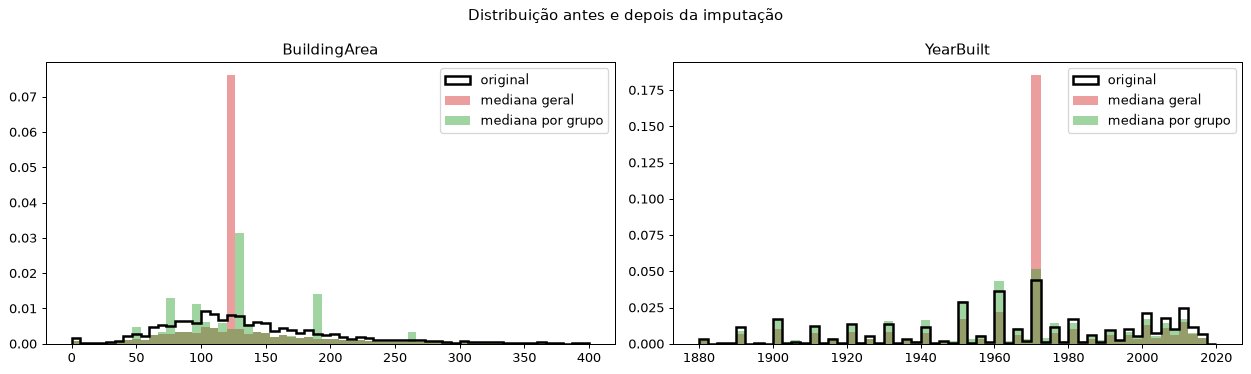

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
cfg = [('BuildingArea', np.linspace(0, 400, 61)), ('YearBuilt', np.linspace(1880, 2020, 57))]
for ax, (col, bins) in zip(axes, cfg):
    ax.hist(df[col].dropna(), bins=bins, density=True, histtype='step', lw=2, color='black', label='original')
    ax.hist(df_imput_simples[col], bins=bins, density=True, alpha=0.45, color='tab:red', label='mediana geral')
    ax.hist(df_imputacao[col], bins=bins, density=True, alpha=0.45, color='tab:green', label='mediana por grupo')
    ax.set_title(col)
    ax.legend()
plt.suptitle('Distribuição antes e depois da imputação')
plt.tight_layout()
plt.show()

**Comparação**
- **Linhas:** a remoção escolhida mantém **13.518 linhas (99,5%)**, mas fica com 18 colunas. Se eu tivesse apagado toda linha com nulo, sobrariam só **6.196 (45,6%)**, e o perfil da base mudaria: a mediana de `Price` cairia de 903 mil para 880 mil e a de `Landsize` de 440 para 373 m², ou seja, a amostra que sobra não representa mais a original. Na remoção escolhida essas medianas quase não se mexem (901 mil e 442,5 m²). As imputações mantêm as **13.580 linhas**.
- **Média e mediana:** a mediana geral, por construção, não muda a mediana da coluna (126 m², 1970), mas **joga milhares de imóveis no mesmo valor**, o que encolhe o desvio-padrão (`YearBuilt`: 37,3 → 29,1) e cria um **pico artificial** no histograma.
- A **imputação por grupo** também reduz a variação, porém menos: o desvio de `YearBuilt` fica em 34,2 e o histograma (verde) acompanha melhor a forma original, porque cada grupo recebe um valor diferente. A mediana de `YearBuilt` cai para 1965 porque as casas (`h`), tipo mais comum entre os imóveis sem ano, são mais antigas que a média.
- Em `Car` as três versões praticamente coincidem: com só 62 valores faltando, qualquer escolha serve.

## Respostas às perguntas de reflexão

In [13]:
# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO — números de apoio
apoio = df[['Price', 'Landsize']].agg(['mean', 'median', 'max', 'skew']).T
apoio['diferença média x mediana (%)'] = (apoio['mean'] / apoio['median'] - 1) * 100
display(apoio)

# Imóveis SEM BuildingArea são diferentes dos que têm? (pergunta 3)
print('Preço mediano — com BuildingArea:', df.loc[df['BuildingArea'].notna(), 'Price'].median(),
      '| sem BuildingArea:', df.loc[df['BuildingArea'].isna(), 'Price'].median())

,mean,median,max,skew,diferença média x mediana (%)
Price,"1,075,684.08","903,000.00","9,000,000.00",2.24,19.12
Landsize,558.42,440.00,"433,014.00",95.24,26.91


Preço mediano — com BuildingArea: 895000.0 | sem BuildingArea: 917000.0


**1. Coluna com mais da metade dos valores ausentes: imputar ou descartar?**
Não existe um número mágico. Eu levaria em conta:
- **o papel da coluna no objetivo**: se ela é central para a análise de preço, vale tentar outra fonte de dados ou imputar com cuidado; se é acessória, descartar é mais honesto;
- **o mecanismo da falta**: se a falta é aleatória, imputar distorce pouco; se depende de algo (como vimos com ano de venda e tipo de imóvel), a imputação pode carregar viés;
- **o que sobra de informação real**: acima de 50%, a maior parte da coluna passa a ser "opinião" do método;
- **se existem variáveis que ajudam a prever o valor**: aí uma imputação por grupo ou por modelo (KNN) fica mais defensável.

Aqui descartei `BuildingArea` e `YearBuilt` na estratégia de remoção e, na de imputação, mantive as duas **com indicador de ausência**, para que um modelo possa testar se elas ajudam mesmo.

**2. Para `Price` e `Landsize`, média e mediana dariam valores parecidos? Qual é mais segura?**
Não. A média de `Price` fica cerca de **19% acima** da mediana e a de `Landsize`, cerca de **27% acima**. As duas colunas têm assimetria positiva (cauda longa à direita): `Landsize` chega a 433.014 m² e `Price` a 9 milhões. Esses poucos valores enormes puxam a média para cima. A **mediana é mais segura** porque depende só da posição central dos dados e não se mexe por causa de meia dúzia de mansões.

**3. Quando a ausência é, por si só, uma informação útil?**
Quando o motivo da falta tem relação com o fenômeno estudado. Exemplos:
- num formulário de crédito, quem **deixa a renda em branco** costuma ter perfil de risco diferente;
- num prontuário, um **exame não pedido** diz algo sobre a suspeita do médico;
- nesta base, a falta de `BuildingArea` muda conforme o ano e o tipo de venda, o que sugere que alguns anunciantes não informam a área. Se isso estiver ligado ao preço, o indicador `BuildingArea_faltava` vira uma variável útil. (Aqui o preço mediano dos dois grupos é parecido, 895 mil com área e 917 mil sem área, então o sinal parece fraco, mas só um modelo confirmaria.)

## Desafio — KNNImputer
O `KNNImputer` estima cada valor ausente pela média dos *k* imóveis mais parecidos nas outras colunas. Apliquei em `BuildingArea`, com dois cuidados:
1. **escala**: o KNN mede distância, então padronizo as variáveis de apoio (senão `Price`, na casa do milhão, dominaria a conta);
2. **assimetria**: aplico o KNN no **log** da área e depois volto para m², para que as mansões não puxem a média dos vizinhos.

In [14]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

def imputar_area_knn(base, k=7):
    apoio = base[['Rooms', 'Bathroom', 'Bedroom2', 'Distance', 'Lattitude', 'Longtitude']].copy()
    apoio['Car'] = df_imputacao['Car']                 # Car já sem nulos
    apoio['log_Landsize'] = np.log1p(base['Landsize'])
    apoio['log_Price'] = np.log(base['Price'])
    X = pd.DataFrame(StandardScaler().fit_transform(apoio), columns=apoio.columns, index=base.index)
    X['log_area'] = np.log1p(base['BuildingArea'])
    preenchido = KNNImputer(n_neighbors=k).fit_transform(X)[:, -1]
    return pd.Series(np.expm1(preenchido), index=base.index)

area_knn = imputar_area_knn(df)

pd.DataFrame({
    'original': df['BuildingArea'].describe(),
    'mediana geral': df_imput_simples['BuildingArea'].describe(),
    'mediana por grupo': df_imputacao['BuildingArea'].describe(),
    'KNN (k=7)': area_knn.describe(),
}).loc[['count', 'mean', '50%', 'std']]

,original,mediana geral,mediana por grupo,KNN (k=7)
count,"7,130.00","13,580.00","13,580.00","13,580.00"
mean,151.97,139.63,141.45,141.61
50%,126.00,126.00,130.00,123.00
std,541.01,392.22,393.55,393.99


In [15]:
# Validação: escondo 10% das áreas conhecidas, imputo de novo e comparo com o valor verdadeiro
rng = np.random.default_rng(2024)
conhecidas = df.index[df['BuildingArea'] > 0]
teste = rng.choice(conhecidas, size=int(len(conhecidas) * 0.10), replace=False)

df_teste = df.copy()
verdade = df_teste.loc[teste, 'BuildingArea']
df_teste.loc[teste, 'BuildingArea'] = np.nan

previsoes = {
    'mediana geral': pd.Series(df_teste['BuildingArea'].median(), index=teste),
    'mediana por grupo': mediana_por_grupo(df_teste, 'BuildingArea', [['Type', 'Rooms'], ['Type']]).loc[teste],
    'KNN (k=7)': imputar_area_knn(df_teste).loc[teste],
}
erros = pd.DataFrame({
    nome: {'erro absoluto médio (m²)': (p - verdade).abs().mean(),
           'erro absoluto mediano (m²)': (p - verdade).abs().median(),
           'erro percentual mediano (%)': ((p - verdade).abs() / verdade).median() * 100}
    for nome, p in previsoes.items()
}).T
erros

,erro absoluto médio (m²),erro absoluto mediano (m²),erro percentual mediano (%)
mediana geral,51.74,39.00,29.90
mediana por grupo,34.06,21.00,16.67
KNN (k=7),33.54,19.85,15.96


**O que muda com o KNN e quanto ele custa**
- **Resultado:** o KNN dá a cada imóvel uma área própria, coerente com quartos, banheiros, terreno, preço e localização. Na validação, ele erra bem menos que a mediana geral (erro mediano de cerca de 20 m² contra 39 m²).
- **Mas o ganho sobre a mediana por grupo é pequeno:** a mediana por `Type` + `Rooms` erra praticamente o mesmo (cerca de 21 m²). Ou seja, quase toda a melhora vem de **usar o grupo certo**, e não da sofisticação do algoritmo.
- **Custos do KNN:** (1) é bem mais lento, porque calcula distâncias entre milhares de linhas; (2) exige escolher *k*, as variáveis de apoio e a escala; (3) é mais difícil de explicar para quem vai usar os dados; (4) se aplicado antes de separar treino e teste, um imóvel do teste "ajuda" a preencher o treino (**vazamento**); (5) continua sendo um valor estimado.
- **Conclusão:** para esta base eu ficaria com a **mediana por grupo + indicador de ausência**: quase o mesmo erro, muito mais simples e transparente.

## Resumo final
| Versão | Linhas | Colunas | Prós | Contras |
|---|---|---|---|---|
| `df_remocao` | 13.518 | 18 | nenhum valor inventado, perde só 0,5% das linhas | perde área, ano e município |
| `df_imput_simples` | 13.580 | 21 | simples | pico artificial e variância achatada |
| `df_imputacao` (por grupo) | 13.580 | 23 | mantém tudo e respeita diferenças entre grupos | valores estimados; precisa do indicador |
| KNN (desafio) | 13.580 | — | estimativa individual | caro e quase sem ganho sobre o grupo |

O DataFrame original `df` não foi alterado em nenhum momento.